# E12-H64 - anisotropy decomposition: centering vs projection

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - attributing the E01-H3 anisotropy gain to one of its three internal operations

The shipped `all_but_the_top(k=1)` lever (`docdistance/distance.py:94-115`) is three separable operations
released as one: it subtracts the pooled mean (line 104), projects out the top principal component of the
*centered* matrix (line 107), and re-L2-normalizes (line 108). E01-H3 promoted the composition on the
11-summary IBM fixture (margin +4.58 -> +18.48 closeness points, dynamic range 0.0854 -> 0.2286, `V` 0/24),
and the docstring credits the projection. This notebook decomposes the lever and asks which operation
actually carries the gain.

**Arms** (each scored on the same E01 panel, all pairs anchored on `gold`)

- **a - center + renorm** - subtract the pooled mean, re-L2-normalize; no SVD at all
- **b - project only (mean restored)** - center, project out PC1, add the pooled mean back, re-L2-normalize;
  the clean projection isolate. The naive "project the uncentered matrix" arm is confounded because the
  uncentered top singular vector is almost exactly the mean direction, so it silently performs the centering
- **c - full shipped composition** - `all_but_the_top(k=1)` verbatim, the E01-H3 reproduction

**Approach**
1. **Kill-gate** - re-encode the fixture and read the norm of the pooled statement mean; below 0.15 the
   common mean carries no anisotropy and the centering arm dies before any panel run
2. **Harness sanity check** - reproduce the naive baseline row (margin +4.58, `R` 1.68, `DR` 0.0854,
   `d'` 4.60, `V` 0/24) and the E01-H3 full-composition row (+18.48, `DR` 0.2286) with the shipped
   OpenVINO INT8 encoder before any arm is scored
3. **Score the three arms** on the E01 panel - `V`, margin, `d'`, `R`, `DR`
4. **Diagnostic** - `cos(uncentered PC1, mean direction)`, the number that explains why the naive
   projection arm would have been confounded
5. **Guardrails** - `V` counted per arm, default-path `smd` / `order_gap` bit-identity by byte diff,
   metric property (unit norms, cost identity, triangle inequality), shipped defaults untouched
6. **Acceptance bar** - attribution stands if exactly one arm reaches >= 60% of the full-composition
   margin gain at `V` 0/24 with the metric property intact

## Environment

No GPU: the workstation's cards are held by foreign jobs, so CUDA is masked out before any import and the
whole run is CPU (OpenVINO INT8 mmBERT, CPU SaT segmenter, numpy/POT transport). Model resolution is
offline through the repo's `docdistance.json` mirror.

In [1]:
import os
import logging
import warnings

os.environ["CUDA_VISIBLE_DEVICES"] = ""       # CPU only - the GPUs are held by foreign jobs
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

warnings.filterwarnings("ignore")
for _n in ("torch", "transformers", "huggingface_hub", "openvino", "wtpsplit"):
    logging.getLogger(_n).setLevel(logging.ERROR)

print("device: CPU (CUDA masked)")

device: CPU (CUDA masked)


## Imports

Numpy and POT for the transport core, matplotlib/seaborn for the inline panels, rich for the tables, and the
shipped `docdistance` functions (`smd`, `closeness`, `cost_matrix`, `all_but_the_top`, `compute_distance`,
`compute_structural`) so every arm is scored through production code rather than a private re-implementation.

In [2]:
import contextlib
import io
import json
import struct
import subprocess
import time
from pathlib import Path

import numpy as np
import ot
import matplotlib.pyplot as plt
import seaborn as sns
from rich.console import Console
from rich.table import Table
from rich.panel import Panel

import docdistance
from docdistance.distance import (
    all_but_the_top,
    closeness,
    compute_distance,
    compute_structural,
    cost_matrix,
    smd,
)
from docdistance.encoders import OpenVINOEncoder, Segmenter

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print(f"docdistance {docdistance.__version__} | POT {ot.__version__} | numpy {np.__version__}")
print(f"package: {Path(docdistance.__file__).parent}")

docdistance 1.1.5 | POT 0.9.6.post1 | numpy 2.4.6
package: /home/lab/workspace/learning/projects/docdistance/src/docdistance


## Reproducibility

One fixed seed. Every step is deterministic: OpenVINO INT8 inference on CPU, an exact network-simplex
transport solve, and a deterministic numpy SVD - no sampling anywhere except the triangle-inequality
spot check, which draws from the seeded generator.

In [3]:
SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)
print(f"SEED={SEED}")

SEED=42


## Configuration

Fixture paths, the eleven-document registry with its tier labels, the registered reference rows this run must
reproduce, the kill-gate threshold and the acceptance bar. The sanity tolerance is declared here, before any
measurement: the registered rows were produced by the torch bf16 GPU encoder and this run re-encodes with the
shipped OpenVINO INT8 encoder, so the panel statistics are compared at 10% relative tolerance with `V` matched
exactly. Every delta is reported so a stricter reading can be applied to the numbers directly.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
METRICS_PATH = ROOT / "reports/E12-H64-centering-vs-projection-metrics.json"

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
REFERENCE = "gold"
LABELS = [l for _, l, _ in DOCS]
TIER = {l: t for _, l, t in DOCS}
GOLD = [l for l in LABELS if TIER[l] == "gold" and l != REFERENCE]
ADV = [l for l in LABELS if TIER[l] in ("adv1", "adv2")]
NONREF = [l for l in LABELS if l != REFERENCE]
TIER_COLOR = {"gold": "#2ca02c", "adv1": "#ff7f0e", "adv2": "#d62728"}

SMD_MAX = float(np.sqrt(2.0))
K = 1                       # the shipped anisotropy setting (all_but_the_top k=1)
GATE_MIN_MEAN_NORM = 0.15   # kill-gate: ||pooled mean|| below this and centering cannot be the cause
BAR_RECOVERY = 0.60         # acceptance bar: >= 60% of the full-composition margin gain
SANITY_RTOL = 0.10          # executor-declared INT8 re-encode band; the record registers no tolerance
SANITY_RTOL_STRICT = 0.05   # the stricter band declared by the sibling hypothesis H66, reported alongside
SANITY_REQUIRED_ROW = "baseline"   # the row the campaign primer requires H64 to reproduce

# registered reference rows (docs/experiments/wmd-docdistance-experiments.md, E01 results table)
REGISTERED = {
    "baseline": dict(V=0, margin_pts=4.58, dprime=4.60, R=1.680, DR=0.0854),
    "full":     dict(V=0, margin_pts=18.48, dprime=7.17, R=1.482, DR=0.2286),
}
# Two denominators for the recovery fraction. The bar is scored on this run's own re-encoded gain
# (arm c minus the naive baseline, both measured here); the registered gain (+4.58 -> +18.48 = 13.90 pts)
# from the record's hypothesis text is reported next to it so either reading can be applied.
FULL_GAIN_REGISTERED = REGISTERED["full"]["margin_pts"] - REGISTERED["baseline"]["margin_pts"]

# registered prediction, checked verbatim in its own section below
PRED_MARGIN_BAND = (12.0, 18.0)   # centering-only margin, closeness points
PRED_DR_MULT = 2.0                # centering-only DR >= 2x the registered 0.0854 baseline

cfg = Table(title="E12-H64 configuration", header_style="bold cyan")
cfg.add_column("key"); cfg.add_column("value", style="bold")
for k, v in [
    ("fixture", "ibm-ai-adoption 11 exec summaries"),
    ("anchor", REFERENCE),
    ("gold / adversarial", f"{len(GOLD)} / {len(ADV)}  ->  V out of {len(GOLD) * len(ADV)}"),
    ("encoder", "mmBERT OpenVINO INT8 (CPU)"),
    ("segmenter", "SaT sat-3l-sm (CPU, plain prose split)"),
    ("arms", "a center+renorm | b project-only (mean restored) | c full shipped"),
    ("kill-gate", f"||pooled mean|| >= {GATE_MIN_MEAN_NORM}"),
    ("acceptance bar", f"exactly one arm >= {BAR_RECOVERY:.0%} of the full margin gain at V=0"),
    ("sanity tolerance", f"{SANITY_RTOL:.0%} relative (executor-declared), V exact; "
                         f"{SANITY_RTOL_STRICT:.0%} also reported"),
    ("registered full gain", f"{FULL_GAIN_REGISTERED:+.2f} pts (+4.58 -> +18.48)"),
    ("registered prediction", f"margin in [{PRED_MARGIN_BAND[0]:+.0f}, {PRED_MARGIN_BAND[1]:+.0f}] pts, "
                              f"DR >= {PRED_DR_MULT:.0f}x 0.0854"),
    ("metrics json", str(METRICS_PATH.relative_to(ROOT))),
]:
    cfg.add_row(k, str(v))
console.print(cfg)

                                    E12-H64 configuration                                    
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ key                   ┃ value                                                             ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ fixture               │ ibm-ai-adoption 11 exec summaries                                 │
│ anchor                │ gold                                                              │
│ gold / adversarial    │ 6 / 4  ->  V out of 24                                            │
│ encoder               │ mmBERT OpenVINO INT8 (CPU)                                        │
│ segmenter             │ SaT sat-3l-sm (CPU, plain prose split)                            │
│ arms                  │ a center+renorm | b project-only (mean restored) | c full shipped │
│ kill-gate             │ ||pooled mean|| >= 0.15                                           │
│ acceptance bar        │ exactly one arm >= 60% of the full margin gain at V=0             │
│ sanity tolerance      │ 10% relative (executor-declared), V exact; 5% also reported       │
│ registered full gain  │ +13.90 pts (+4.58 -> +18.48)                                      │
│ registered prediction │ margin in [+12, +18] pts, DR >= 2x 0.0854                         │
│ metrics json          │ reports/E12-H64-centering-vs-projection-metrics.json              │
└───────────────────────┴───────────────────────────────────────────────────────────────────┘

## Fixture - segmentation and embedding

Load each summary's body (the markdown title line is dropped, as in E01), segment it into statements with the
shipped SaT segmenter, and embed every statement with the shipped OpenVINO INT8 mmBERT encoder. This single
re-encode feeds the kill-gate, the sanity check and all three arms. The default-path guardrail snapshot is
taken here, on the raw embeddings, before any geometry is touched.

In [5]:
def load_body(path: Path) -> str:
    return "\n".join(l for l in path.read_text().splitlines() if not l.startswith("# ")).strip()


texts = {label: load_body(SUMMARY_DIR / fname) for fname, label, _ in DOCS}

t0 = time.perf_counter()
with contextlib.redirect_stderr(io.StringIO()):
    segmenter = Segmenter(offline=True)
    encoder = OpenVINOEncoder(offline=True)
    statements = {l: segmenter.split(t) for l, t in texts.items()}
    emb = {l: encoder.encode(s) for l, s in statements.items()}
load_s = time.perf_counter() - t0

POOL = np.concatenate([emb[l] for l in LABELS], 0)
N_STATEMENTS = len(POOL)

# default-path guardrail snapshot: raw embedding bytes + shipped smd / order_gap on a fixed pair
GUARD_PAIR = ("gold", "opus")
EMB_BYTES_BEFORE = {l: emb[l].tobytes() for l in LABELS}
_ga, _gb = emb[GUARD_PAIR[0]], emb[GUARD_PAIR[1]]
SMD_BEFORE = compute_distance(_ga, _gb).smd
GAP_BEFORE = compute_structural(_ga, _gb).order_gap
hexf = lambda x: struct.pack("<d", x).hex()

tbl = Table(title=f"fixture - {N_STATEMENTS} statements over {len(LABELS)} documents", header_style="bold cyan")
tbl.add_column("doc"); tbl.add_column("tier"); tbl.add_column("statements", justify="right")
for l in LABELS:
    tbl.add_row(l, TIER[l], str(len(statements[l])))
console.print(tbl)
console.print(Panel(
    f"embedding dim {POOL.shape[1]} | load+encode {load_s:.1f}s\n"
    f"default-path snapshot on {GUARD_PAIR[0]} vs {GUARD_PAIR[1]}: "
    f"smd={SMD_BEFORE:.12f} (0x{hexf(SMD_BEFORE)}), order_gap={GAP_BEFORE:.12f} (0x{hexf(GAP_BEFORE)})",
    title="fixture ready", border_style="cyan"))

 fixture - 98 statements over 
         11 documents         
┏━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┓
┃ doc    ┃ tier ┃ statements ┃
┡━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━┩
│ gold   │ gold │         10 │
│ gold-2 │ gold │         12 │
│ v1     │ gold │         11 │
│ v2     │ gold │         11 │
│ opus   │ gold │         11 │
│ sonnet │ gold │          9 │
│ haiku  │ gold │         13 │
│ adv1-a │ adv1 │          8 │
│ adv1-b │ adv1 │          9 │
│ adv2-a │ adv2 │          1 │
│ adv2-b │ adv2 │          3 │
└────────┴──────┴────────────┘

╭───────────────────────────────────────────────── fixture ready ─────────────────────────────────────────────────╮
│ embedding dim 768 | load+encode 52.4s                                                                           │
│ default-path snapshot on gold vs opus: smd=0.236586306041 (0x7c4a90c77548ce3f), order_gap=0.133077409921        │
│ (0x0264b939ae08c13f)                                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate - norm of the pooled statement mean

The registered gate: the statement embeddings are unit-norm, so the norm of their pooled mean is the direct
read on how much common direction they share. Below 0.15 the common mean carries no meaningful anisotropy,
centering cannot be the cause, and the centering arm dies here.

In [6]:
mean_vec = POOL.mean(0)
mean_norm = float(np.linalg.norm(mean_vec))
GATE_PASSED = bool(mean_norm >= GATE_MIN_MEAN_NORM)

unit_dev = float(np.abs(np.linalg.norm(POOL, axis=1) - 1.0).max())
console.print(Panel(
    f"||pooled mean|| = [bold]{mean_norm:.4f}[/bold]   threshold {GATE_MIN_MEAN_NORM}\n"
    f"pooled statements: {N_STATEMENTS}, max |‖x‖-1| = {unit_dev:.2e} (inputs are unit-norm)\n"
    f"gate: [bold]{'PASSED - centering arm proceeds' if GATE_PASSED else 'KILLED - run ends here'}[/bold]",
    title="kill-gate", border_style="green" if GATE_PASSED else "red"))
if not GATE_PASSED:
    raise SystemExit("kill-gate failed")

╭─────────────────────────────────────────────────── kill-gate ───────────────────────────────────────────────────╮
│ ||pooled mean|| = 0.9539   threshold 0.15                                                                       │
│ pooled statements: 98, max |‖x‖-1| = 1.79e-07 (inputs are unit-norm)                                            │
│ gate: PASSED - centering arm proceeds                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Panel machinery

The E01 scoring panel, unchanged: distance from every non-anchor summary to `gold`, closeness on the
`sqrt(2)` scale, and the five statistics - `V` (gold/adversarial ordinality violations out of 24), margin
(min gold closeness minus max adversarial closeness, in closeness points), `d'`, `R`, `DR`.

In [7]:
def panel(eb: dict) -> dict:
    """E01 panel over a geometry: distances to the anchor plus V / margin / d' / R / DR."""
    dist = {l: smd(eb[l], eb[REFERENCE]) for l in NONREF}
    g = np.array([dist[l] for l in GOLD])
    a = np.array([dist[l] for l in ADV])
    clos = {l: closeness(dist[l]) for l in NONREF}
    gc = np.array([clos[l] for l in GOLD])
    ac = np.array([clos[l] for l in ADV])
    pooled = float(np.sqrt((g.var() + a.var()) / 2)) or 1e-9
    return dict(
        dist=dist, clos=clos,
        V=int(sum(1 for gg in g for aa in a if gg >= aa)),
        margin_pts=float(gc.min() - ac.max()) * 100.0,
        dprime=float((a.mean() - g.mean()) / pooled),
        R=float(a.mean() / g.mean()),
        DR=float(np.concatenate([g, a]).std()),
    )


def repack(fixed: np.ndarray) -> dict:
    """Split a transformed pooled matrix back into the per-document embedding dict."""
    out, off = {}, 0
    for l in LABELS:
        n = len(emb[l])
        out[l] = fixed[off:off + n].astype(np.float32)
        off += n
    return out


def l2(M: np.ndarray) -> np.ndarray:
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)


print("panel ready:", ", ".join(["V", "margin_pts", "dprime", "R", "DR"]))

panel ready: V, margin_pts, dprime, R, DR


## Harness sanity check

Before any arm is scored, reproduce two registered rows on this re-encode: the naive baseline
(margin +4.58, `d'` 4.60, `R` 1.680, `DR` 0.0854, `V` 0/24), which the campaign primer requires for this
hypothesis, and the E01-H3 full composition (margin +18.48, `DR` 0.2286), which is optional here and is
carried because arm c reproduces it. A row passes when `V` matches exactly and every panel statistic is
within the 10% band. That band is the executor's declaration, made in the configuration cell before any
measurement - the record and the primer register no tolerance - so the stricter 5% band used by the
sibling hypothesis H66 is reported in the same table and every relative delta is printed for a reader who
wants a different reading.

In [8]:
base = panel(emb)
full = panel(all_but_the_top(emb, k=K))
observed = {"baseline": base, "full": full}

sanity_rows, sanity_ok = [], True
strict_ok = {row: True for row in REGISTERED}
for row in ("baseline", "full"):
    reg, obs = REGISTERED[row], observed[row]
    for stat in ("margin_pts", "dprime", "R", "DR"):
        rel = abs(obs[stat] - reg[stat]) / abs(reg[stat])
        ok = rel <= SANITY_RTOL
        sanity_ok &= ok
        strict_ok[row] &= rel <= SANITY_RTOL_STRICT
        sanity_rows.append((row, stat, reg[stat], obs[stat], rel, ok))
    ok_v = obs["V"] == reg["V"]
    sanity_ok &= ok_v
    strict_ok[row] &= ok_v
    sanity_rows.append((row, "V", reg["V"], obs["V"], 0.0, ok_v))

t = Table(title="harness sanity check - registered row vs this re-encode", header_style="bold cyan")
for c, j in [("row", "left"), ("stat", "left"), ("registered", "right"), ("observed", "right"),
             ("rel delta", "right"), (f"within {SANITY_RTOL:.0%}", "left"),
             (f"within {SANITY_RTOL_STRICT:.0%}", "left")]:
    t.add_column(c, justify=j)
for row, stat, reg, obs, rel, ok in sanity_rows:
    t.add_row(row, stat, f"{reg:.4f}", f"{obs:.4f}", f"{rel * 100:.2f}%",
              "[green]yes[/green]" if ok else "[red]no[/red]",
              "[green]yes[/green]" if rel <= SANITY_RTOL_STRICT else "[yellow]no[/yellow]")
console.print(t)
SANITY_PASSED = bool(sanity_ok)
SANITY_STRICT_BY_ROW = {row: bool(v) for row, v in strict_ok.items()}
MAX_REL_DELTA_BY_ROW = {row: max(r[4] for r in sanity_rows if r[0] == row) for row in REGISTERED}
console.print(Panel(
    f"sanity check: [bold]{'PASSED' if SANITY_PASSED else 'FAILED'}[/bold] at the executor-declared "
    f"{SANITY_RTOL:.0%} band (V {base['V']}/24 baseline, {full['V']}/24 full)\n"
    f"required row ({SANITY_REQUIRED_ROW}): max rel delta {MAX_REL_DELTA_BY_ROW[SANITY_REQUIRED_ROW] * 100:.2f}%, "
    f"also within {SANITY_RTOL_STRICT:.0%}: {SANITY_STRICT_BY_ROW[SANITY_REQUIRED_ROW]}\n"
    f"optional row (full): max rel delta {MAX_REL_DELTA_BY_ROW['full'] * 100:.2f}%, "
    f"also within {SANITY_RTOL_STRICT:.0%}: {SANITY_STRICT_BY_ROW['full']}",
    border_style="green" if SANITY_PASSED else "red"))
if not SANITY_PASSED:
    raise SystemExit("harness sanity check failed - Blocked")

               harness sanity check - registered row vs this re-encode                
┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ row      ┃ stat       ┃ registered ┃ observed ┃ rel delta ┃ within 10% ┃ within 5% ┃
┡━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ baseline │ margin_pts │     4.5800 │   4.7083 │     2.80% │ yes        │ yes       │
│ baseline │ dprime     │     4.6000 │   4.6840 │     1.83% │ yes        │ yes       │
│ baseline │ R          │     1.6800 │   1.6697 │     0.61% │ yes        │ yes       │
│ baseline │ DR         │     0.0854 │   0.0873 │     2.20% │ yes        │ yes       │
│ baseline │ V          │     0.0000 │   0.0000 │     0.00% │ yes        │ yes       │
│ full     │ margin_pts │    18.4800 │  19.4144 │     5.06% │ yes        │ no        │
│ full     │ dprime     │     7.1700 │   7.3100 │     1.95% │ yes        │ yes       │
│ full     │ R          │     1.4820 │   1.4755 │     0.44% │ yes        │ yes       │
│ full     │ DR         │     0.2286 │   0.2253 │     1.43% │ yes        │ yes       │
│ full     │ V          │     0.0000 │   0.0000 │     0.00% │ yes        │ yes       │
└──────────┴────────────┴────────────┴──────────┴───────────┴────────────┴───────────┘

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ sanity check: PASSED at the executor-declared 10% band (V 0/24 baseline, 0/24 full)                             │
│ required row (baseline): max rel delta 2.80%, also within 5%: True                                              │
│ optional row (full): max rel delta 5.06%, also within 5%: False                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## The three arms

Arm a subtracts the pooled mean and re-normalizes. Arm b centers, projects out the top principal component of
the centered matrix, adds the mean back and re-normalizes, so the only thing it removes relative to the raw
geometry is the PC1 variation. Arm c is the shipped composition. Each arm is scored on the same panel and its
margin gain is expressed as a fraction of arm c's gain over the naive baseline.

In [9]:
centered = POOL - mean_vec
_, sv_centered, Vt_centered = np.linalg.svd(centered, full_matrices=False)
pc1_centered = Vt_centered[:K]

ARMS = {
    "a center+renorm": repack(l2(centered)),
    "b project-only":  repack(l2(centered - centered @ pc1_centered.T @ pc1_centered + mean_vec)),
    "c full shipped":  all_but_the_top(emb, k=K),
}
SCORE = {"baseline": base, **{name: panel(eb) for name, eb in ARMS.items()}}

FULL_GAIN = SCORE["c full shipped"]["margin_pts"] - base["margin_pts"]
RECOVERY = {n: (SCORE[n]["margin_pts"] - base["margin_pts"]) / FULL_GAIN for n in ARMS}
RECOVERY_REGISTERED = {n: (SCORE[n]["margin_pts"] - base["margin_pts"]) / FULL_GAIN_REGISTERED
                       for n in ARMS}   # same gains over the registered +13.90 pt denominator

t = Table(title="E12-H64 arms on the E01 panel (anchor = gold, 24 gold/adversarial pairs)",
          header_style="bold cyan")
for c, j in [("arm", "left"), ("V", "right"), ("margin (pts)", "right"), ("gain (pts)", "right"),
             ("recovery", "right"), ("recovery (reg. denom)", "right"), ("d'", "right"), ("R", "right"),
             ("DR", "right"), ("DR x base", "right")]:
    t.add_column(c, justify=j)
for name in ["baseline", *ARMS]:
    r = SCORE[name]
    gain = r["margin_pts"] - base["margin_pts"]
    rec = "-" if name == "baseline" else f"{RECOVERY[name] * 100:.1f}%"
    rec_reg = "-" if name == "baseline" else f"{RECOVERY_REGISTERED[name] * 100:.1f}%"
    vcol = "green" if r["V"] == 0 else "red"
    t.add_row(name, f"[{vcol}]{r['V']}/24[/{vcol}]", f"{r['margin_pts']:+.2f}",
              "-" if name == "baseline" else f"{gain:+.2f}", rec, rec_reg,
              f"{r['dprime']:.2f}", f"{r['R']:.3f}", f"{r['DR']:.4f}", f"{r['DR'] / base['DR']:.2f}x")
console.print(t)
console.print(Panel(f"full-composition margin gain (this run, the bar's denominator) = "
                    f"[bold]{FULL_GAIN:+.2f}[/bold] pts "
                    f"({base['margin_pts']:+.2f} -> {SCORE['c full shipped']['margin_pts']:+.2f})\n"
                    f"registered gain (E01-H3, +4.58 -> +18.48) = [bold]{FULL_GAIN_REGISTERED:+.2f}[/bold] pts; "
                    f"arm a recovery reads {RECOVERY['a center+renorm'] * 100:.1f}% on this run's denominator "
                    f"and {RECOVERY_REGISTERED['a center+renorm'] * 100:.1f}% on the registered one, "
                    f"arm b {RECOVERY['b project-only'] * 100:.1f}% and "
                    f"{RECOVERY_REGISTERED['b project-only'] * 100:.1f}%",
                    border_style="cyan"))

                     E12-H64 arms on the E01 panel (anchor = gold, 24 gold/adversarial pairs)                      
┏━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┓
┃               ┃      ┃              ┃            ┃          ┃      recovery ┃      ┃       ┃        ┃           ┃
┃ arm           ┃    V ┃ margin (pts) ┃ gain (pts) ┃ recovery ┃  (reg. denom) ┃   d' ┃     R ┃     DR ┃ DR x base ┃
┡━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━┩
│ baseline      │ 0/24 │        +4.71 │          - │        - │             - │ 4.68 │ 1.670 │ 0.0873 │     1.00x │
│ a             │ 0/24 │       +19.95 │     +15.24 │   103.7% │        109.7% │ 7.38 │ 1.614 │ 0.2712 │     3.11x │
│ center+renorm │      │              │            │          │               │      │       │        │           │
│ b             │ 0/24 │        +4.04 │      -0.66 │    -4.5% │         -4.8% │ 6.32 │ 1.474 │ 0.0588 │     0.67x │
│ project-only  │      │              │            │          │               │      │       │        │           │
│ c full        │ 0/24 │       +19.41 │     +14.71 │   100.0% │        105.8% │ 7.31 │ 1.475 │ 0.2253 │     2.58x │
│ shipped       │      │              │            │          │               │      │       │        │           │
└───────────────┴──────┴──────────────┴────────────┴──────────┴───────────────┴──────┴───────┴────────┴───────────┘

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ full-composition margin gain (this run, the bar's denominator) = +14.71 pts (+4.71 -> +19.41)                   │
│ registered gain (E01-H3, +4.58 -> +18.48) = +13.90 pts; arm a recovery reads 103.7% on this run's denominator   │
│ and 109.7% on the registered one, arm b -4.5% and -4.8%                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Diagnostic - the uncentered PC1 is the mean direction

The number the record asks for on its own line: the cosine between the top singular vector of the
**uncentered** pooled matrix and the mean direction. A value near 1 is what makes the naive "project the
uncentered matrix" arm useless as a projection isolate - it would remove the mean and be scored as
projection. The centered PC1 is shown next to it as the contrast.

╭─────────────────────────────────── mean direction vs top principal component ───────────────────────────────────╮
│ cos(uncentered PC1, mean direction) = 0.999999                                                                  │
│ cos(centered PC1,   mean direction) = 0.021381                                                                  │
│ top-3 singular values  uncentered [9.444000244140625, 1.5149999856948853, 0.9419999718666077]  centered         │
│ [1.5149999856948853, 0.9449999928474426, 0.8330000042915344]                                                    │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

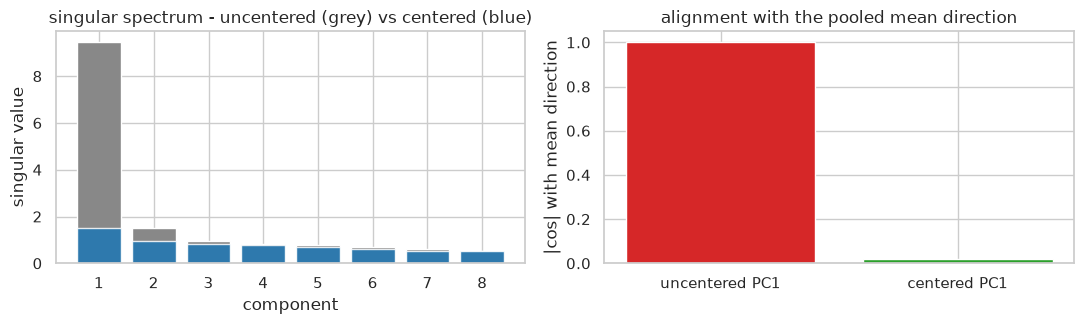

In [10]:
_, sv_uncentered, Vt_uncentered = np.linalg.svd(POOL, full_matrices=False)
mean_dir = mean_vec / np.linalg.norm(mean_vec)
COS_UNCENTERED_PC1_MEAN = float(abs(Vt_uncentered[0] @ mean_dir))
COS_CENTERED_PC1_MEAN = float(abs(Vt_centered[0] @ mean_dir))

console.print(Panel(
    f"cos(uncentered PC1, mean direction) = [bold]{COS_UNCENTERED_PC1_MEAN:.6f}[/bold]\n"
    f"cos(centered PC1,   mean direction) = [bold]{COS_CENTERED_PC1_MEAN:.6f}[/bold]\n"
    f"top-3 singular values  uncentered {np.round(sv_uncentered[:3], 3).tolist()}  "
    f"centered {np.round(sv_centered[:3], 3).tolist()}",
    title="mean direction vs top principal component", border_style="cyan"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(range(1, 9), sv_uncentered[:8], color="#888")
axes[0].bar(range(1, 9), sv_centered[:8], color="#1f77b4", alpha=0.85)
axes[0].set_title("singular spectrum - uncentered (grey) vs centered (blue)")
axes[0].set_xlabel("component"); axes[0].set_ylabel("singular value")
axes[1].bar(["uncentered PC1", "centered PC1"], [COS_UNCENTERED_PC1_MEAN, COS_CENTERED_PC1_MEAN],
            color=["#d62728", "#2ca02c"])
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel("|cos| with mean direction")
axes[1].set_title("alignment with the pooled mean direction")
plt.tight_layout(); plt.show()

## Panels - closeness strips and cosine de-bunching

The tier-closeness strip for each geometry (gold green, adv1 orange, adv2 red, boundary band shaded) and the
pooled pairwise-cosine histograms that show which operation de-bunches the cost matrix.

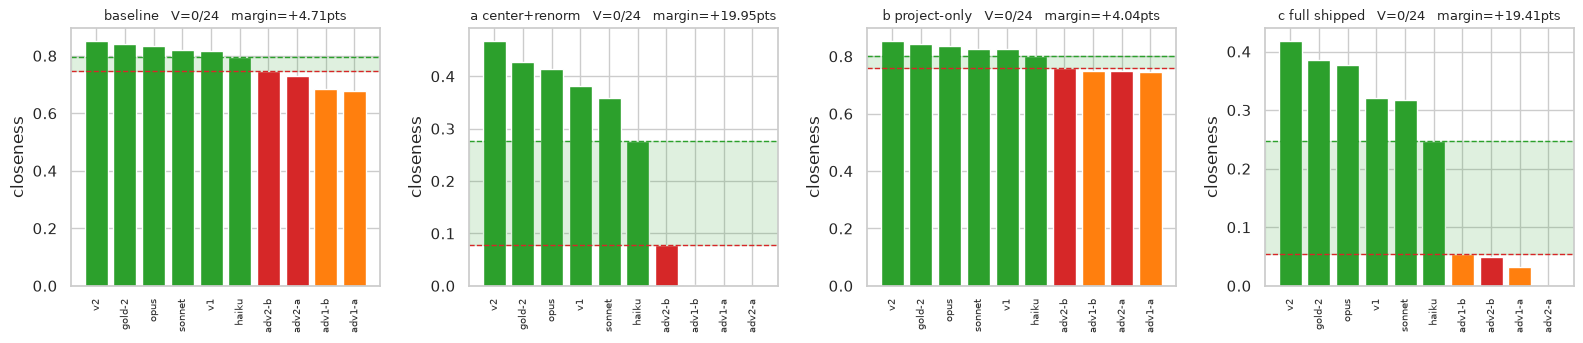

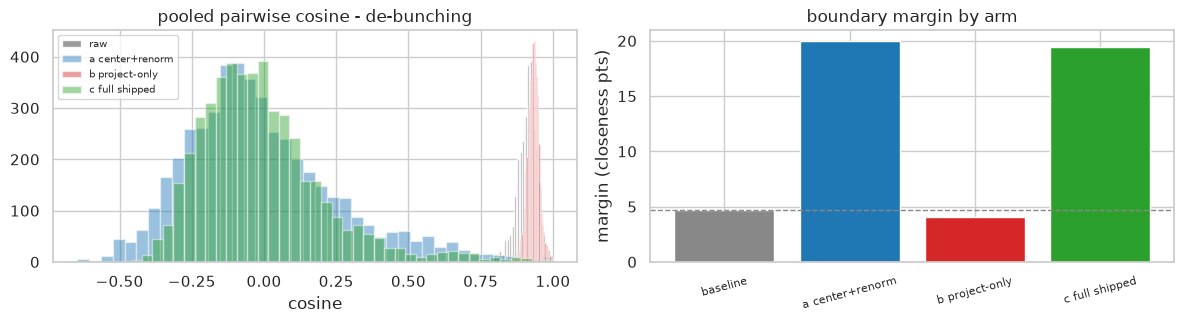

In [11]:
def strip(ax, name):
    r = SCORE[name]
    order = sorted(NONREF, key=lambda l: -r["clos"][l])
    ax.bar(order, [r["clos"][l] for l in order], color=[TIER_COLOR[TIER[l]] for l in order])
    lo = max(r["clos"][l] for l in ADV)
    hi = min(r["clos"][l] for l in GOLD)
    ax.axhspan(min(lo, hi), max(lo, hi), color="#2ca02c" if r["V"] == 0 else "#d62728", alpha=0.15)
    ax.axhline(hi, color="#2ca02c", ls="--", lw=1)
    ax.axhline(lo, color="#d62728", ls="--", lw=1)
    ax.set_title(f"{name}   V={r['V']}/24   margin={r['margin_pts']:+.2f}pts", fontsize=9)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.set_ylabel("closeness")


fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, name in zip(axes, ["baseline", *ARMS]):
    strip(ax, name)
plt.tight_layout(); plt.show()

iu = np.triu_indices(N_STATEMENTS, k=1)
cos_raw = (POOL @ POOL.T)[iu]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(cos_raw, bins=40, color="#888", alpha=0.85, label="raw")
for name, col in zip(ARMS, ["#1f77b4", "#d62728", "#2ca02c"]):
    P = np.concatenate([ARMS[name][l] for l in LABELS], 0)
    axes[0].hist((P @ P.T)[iu], bins=40, alpha=0.45, color=col, label=name)
axes[0].set_title("pooled pairwise cosine - de-bunching"); axes[0].set_xlabel("cosine"); axes[0].legend(fontsize=7)
axes[1].bar(["baseline", *ARMS], [SCORE[n]["margin_pts"] for n in ["baseline", *ARMS]],
            color=["#888", "#1f77b4", "#d62728", "#2ca02c"])
axes[1].axhline(base["margin_pts"], color="#888", ls="--", lw=1)
axes[1].set_ylabel("margin (closeness pts)"); axes[1].set_title("boundary margin by arm")
axes[1].tick_params(axis="x", rotation=15, labelsize=8)
plt.tight_layout(); plt.show()

## Closeness saturation

`closeness()` is `max(0, 1 - d / sqrt(2))` (`distance.py:85-87`), so any distance at or above `sqrt(2)`
clips to zero. The module comment at `distance.py:22` assumes non-negative cosines, which stops holding
once the geometry is centered, so this section counts the clipped documents per geometry and checks the
two documents that actually set the margin - the closest adversarial summary and the most distant gold
one - are both below the ceiling.

In [12]:
SAT_ROWS = []
for name in ["baseline", *ARMS]:
    r = SCORE[name]
    clipped = [l for l in NONREF if r["dist"][l] >= SMD_MAX]
    adv_top = max(ADV, key=lambda l: r["clos"][l])      # the adversary that sets the margin
    gold_bot = min(GOLD, key=lambda l: r["clos"][l])    # the gold summary that sets the margin
    unaffected = bool(r["dist"][adv_top] < SMD_MAX and r["dist"][gold_bot] < SMD_MAX)
    SAT_ROWS.append((name, clipped, adv_top, r["dist"][adv_top], gold_bot, r["dist"][gold_bot], unaffected))
MARGIN_UNAFFECTED_BY_CLIPPING = all(row[-1] for row in SAT_ROWS)

t = Table(title=f"closeness saturation - distances at or above sqrt(2) = {SMD_MAX:.5f}", header_style="bold cyan")
for c, j in [("geometry", "left"), ("clipped docs", "right"), ("which", "left"),
             ("margin adversary", "left"), ("its distance", "right"),
             ("margin gold", "left"), ("its distance", "right"), ("margin unaffected", "left")]:
    t.add_column(c, justify=j)
for name, clipped, adv_top, d_adv, gold_bot, d_gold, unaffected in SAT_ROWS:
    t.add_row(name, str(len(clipped)), ", ".join(clipped) or "-", adv_top, f"{d_adv:.5f}",
              gold_bot, f"{d_gold:.5f}",
              "[green]yes[/green]" if unaffected else "[red]no[/red]")
console.print(t)
console.print(Panel(
    "the margin is min(gold closeness) - max(adversarial closeness); both defining documents stay below "
    f"sqrt(2) in every geometry: [bold]{MARGIN_UNAFFECTED_BY_CLIPPING}[/bold]\n"
    "d', R and DR are computed on raw distances, so clipping cannot reach them; the saturation is inherited "
    "from the shipped E01-H3 composition, which clips adv2-a on this fixture as well",
    border_style="green" if MARGIN_UNAFFECTED_BY_CLIPPING else "red"))

                          closeness saturation - distances at or above sqrt(2) = 1.41421                           
┏━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃             ┃     clipped ┃             ┃ margin       ┃         its ┃             ┃              ┃ margin      ┃
┃ geometry    ┃        docs ┃ which       ┃ adversary    ┃    distance ┃ margin gold ┃ its distance ┃ unaffected  ┃
┡━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ baseline    │           0 │ -           │ adv2-b       │     0.35729 │ haiku       │      0.29071 │ yes         │
│ a           │           2 │ adv1-a,     │ adv2-b       │     1.30479 │ haiku       │      1.02262 │ yes         │
│ center+ren… │             │ adv2-a      │              │             │             │              │             │
│ b           │           0 │ -           │ adv2-b       │     0.33887 │ haiku       │      0.28167 │ yes         │
│ project-on… │             │             │              │             │             │              │             │
│ c full      │           1 │ adv2-a      │ adv1-b       │     1.33811 │ haiku       │      1.06354 │ yes         │
│ shipped     │             │             │              │             │             │              │             │
└─────────────┴─────────────┴─────────────┴──────────────┴─────────────┴─────────────┴──────────────┴─────────────┘

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ the margin is min(gold closeness) - max(adversarial closeness); both defining documents stay below sqrt(2) in   │
│ every geometry: True                                                                                            │
│ d', R and DR are computed on raw distances, so clipping cannot reach them; the saturation is inherited from the │
│ shipped E01-H3 composition, which clips adv2-a on this fixture as well                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Guardrails

Measured, not asserted. `V` is counted per scored arm; the raw embeddings and the default-path `smd` /
`order_gap` are compared byte for byte against the snapshot taken before any arm ran; the metric property is
checked three ways (unit norms after each arm, the cost matrix equal to `sqrt(2 - 2cos)`, and the triangle
inequality over every statement triple), with the shipped raw geometry measured on the same three reads as
the reference row; and the working tree under `src/` and `tests/` is checked clean,
since every arm is prototyped inside this notebook.

In [13]:
# 1 - V per scored arm
V_BY_ARM = {n: SCORE[n]["V"] for n in ["baseline", *ARMS]}
V_ALL_ZERO = all(v == 0 for v in V_BY_ARM.values())

# 2 - default-path bit-identity (byte diff, not allclose)
EMB_UNCHANGED = all(emb[l].tobytes() == EMB_BYTES_BEFORE[l] for l in LABELS)
smd_after = compute_distance(emb[GUARD_PAIR[0]], emb[GUARD_PAIR[1]]).smd
gap_after = compute_structural(emb[GUARD_PAIR[0]], emb[GUARD_PAIR[1]]).order_gap
SMD_BIT_IDENTICAL = struct.pack("<d", smd_after) == struct.pack("<d", SMD_BEFORE)
GAP_BIT_IDENTICAL = struct.pack("<d", gap_after) == struct.pack("<d", GAP_BEFORE)

# 3 - metric property, three reads per geometry, with the shipped raw geometry as the reference row:
#     (i) the vectors are unit-norm to float32 precision, (ii) the ground cost equals sqrt(2 - 2cos)
#     on exactly-unit vectors, (iii) the triangle inequality holds over every (i, j, k) triple.
#     Read (ii) is evaluated on a float64 re-normalized copy: on the float32 arrays the unit-norm
#     residual alone moves the closed form by ~1e-3, an arithmetic band the shipped raw geometry
#     carries identically (the "float32 band" column) - it is rounding, not a different ground cost.
COS_ID_TOL, TRI_TOL, NORM_TOL = 1e-6, 1e-9, 1e-5
GEOMETRIES = {"baseline raw (shipped)": emb, **ARMS}
metric_rows = []
for name, eb in GEOMETRIES.items():
    P32 = np.concatenate([eb[l] for l in LABELS], 0)
    norm_dev = float(np.abs(np.linalg.norm(P32, axis=1) - 1.0).max())
    P64 = P32.astype(np.float64)
    P64 = P64 / np.linalg.norm(P64, axis=1, keepdims=True)      # exactly unit in float64
    C64 = cost_matrix(P64, P64)
    cos_id = float(np.abs(C64 - np.sqrt(np.clip(2.0 - 2.0 * (P64 @ P64.T), 0.0, None))).max())
    C32 = cost_matrix(P32, P32).astype(np.float64)
    band32 = float(np.abs(C32 - np.sqrt(np.clip(2.0 - 2.0 * (P32.astype(np.float64) @ P32.astype(np.float64).T), 0.0, None))).max())
    tri = float((C64[:, None, :] - C64[:, :, None] - C64[None, :, :]).max())  # every (i, j, k) triple
    ok = norm_dev <= NORM_TOL and cos_id <= COS_ID_TOL and tri <= TRI_TOL
    metric_rows.append((name, norm_dev, cos_id, tri, band32, ok))
METRIC_OK = all(r[-1] for r in metric_rows)

# 4 - shipped defaults untouched
tree = subprocess.run(["git", "-C", str(ROOT), "status", "--porcelain", "src", "tests"],
                      capture_output=True, text=True).stdout.strip()
DEFAULTS_UNTOUCHED = tree == ""

t = Table(title="guardrails", header_style="bold cyan")
for c, j in [("guardrail", "left"), ("reading", "left"), ("holds", "left")]:
    t.add_column(c, justify=j)
yn = lambda b: "[green]yes[/green]" if b else "[red]no[/red]"
t.add_row("V per scored arm", " | ".join(f"{n} {v}/24" for n, v in V_BY_ARM.items()), yn(V_ALL_ZERO))
t.add_row("raw embeddings unchanged", f"byte diff over {N_STATEMENTS} statements", yn(EMB_UNCHANGED))
t.add_row("default-path smd bit-identical",
          f"0x{hexf(SMD_BEFORE)} -> 0x{hexf(smd_after)}", yn(SMD_BIT_IDENTICAL))
t.add_row("default-path order_gap bit-identical",
          f"0x{hexf(GAP_BEFORE)} -> 0x{hexf(gap_after)}", yn(GAP_BIT_IDENTICAL))
for name, nd, ci, tri, band32, ok in metric_rows:
    t.add_row(f"metric property - {name}",
              f"max |‖x‖-1| {nd:.1e} | max |C - sqrt(2-2cos)| {ci:.1e} | "
              f"max triangle slack {tri:+.1e} | float32 band {band32:.1e}", yn(ok))
t.add_row("src/ and tests/ clean", tree or "(no modifications)", yn(DEFAULTS_UNTOUCHED))
console.print(t)
GUARDRAILS_OK = bool(V_ALL_ZERO and EMB_UNCHANGED and SMD_BIT_IDENTICAL and GAP_BIT_IDENTICAL
                     and METRIC_OK and DEFAULTS_UNTOUCHED)
print(f"guardrails hold: {GUARDRAILS_OK}")

                                                    guardrails                                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ guardrail                                ┃ reading                                                      ┃ holds ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ V per scored arm                         │ baseline 0/24 | a center+renorm 0/24 | b project-only 0/24 | │ yes   │
│                                          │ c full shipped 0/24                                          │       │
│ raw embeddings unchanged                 │ byte diff over 98 statements                                 │ yes   │
│ default-path smd bit-identical           │ 0x7c4a90c77548ce3f -> 0x7c4a90c77548ce3f                     │ yes   │
│ default-path order_gap bit-identical     │ 0x0264b939ae08c13f -> 0x0264b939ae08c13f                     │ yes   │
│ metric property - baseline raw (shipped) │ max |‖x‖-1| 1.8e-07 | max |C - sqrt(2-2cos)| 4.5e-08 | max   │ yes   │
│                                          │ triangle slack +0.0e+00 | float32 band 5.7e-04               │       │
│ metric property - a center+renorm        │ max |‖x‖-1| 1.2e-07 | max |C - sqrt(2-2cos)| 4.7e-08 | max   │ yes   │
│                                          │ triangle slack +0.0e+00 | float32 band 6.2e-04               │       │
│ metric property - b project-only         │ max |‖x‖-1| 2.4e-07 | max |C - sqrt(2-2cos)| 5.2e-08 | max   │ yes   │
│                                          │ triangle slack +0.0e+00 | float32 band 7.7e-04               │       │
│ metric property - c full shipped         │ max |‖x‖-1| 1.2e-07 | max |C - sqrt(2-2cos)| 4.5e-08 | max   │ yes   │
│                                          │ triangle slack +0.0e+00 | float32 band 4.8e-04               │       │
│ src/ and tests/ clean                    │ (no modifications)                                           │ yes   │
└──────────────────────────────────────────┴──────────────────────────────────────────────────────────────┴───────┘

guardrails hold: True


## Transform cost

The geometry transform is a once-per-corpus step, so this is the cost the lever would drop if the SVD went
away. Phase-1 wall clock is shared across concurrent executors on this machine, so these figures are
indicative of the ratio, not a calibrated latency measurement.

In [14]:
def time_transform(fn, repeats=20):
    fn()
    t0 = time.perf_counter()
    for _ in range(repeats):
        fn()
    return (time.perf_counter() - t0) / repeats * 1e3


COST_MS = {
    "a center+renorm": time_transform(lambda: l2(POOL - POOL.mean(0))),
    "c full shipped": time_transform(lambda: all_but_the_top(emb, k=K)),
}
console.print(Panel(
    f"center+renorm {COST_MS['a center+renorm']:.2f} ms | full composition {COST_MS['c full shipped']:.2f} ms "
    f"over {N_STATEMENTS} statements ({COST_MS['c full shipped'] / COST_MS['a center+renorm']:.1f}x)\n"
    "indicative only - the CPU is shared with concurrent campaign executors",
    title="corpus-level transform cost", border_style="cyan"))

╭────────────────────────────────────────── corpus-level transform cost ──────────────────────────────────────────╮
│ center+renorm 0.07 ms | full composition 506.99 ms over 98 statements (6907.3x)                                 │
│ indicative only - the CPU is shared with concurrent campaign executors                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Prediction check

The record's prediction has three clauses: the centering-only margin lands in [+12, +18] closeness points,
its `DR` is at least twice the registered 0.0854 baseline, and the direction holds - most of the gain
survives without projection while the clean projection-only arm lands near baseline. Each clause is scored
on its own line; the verdict rests on the acceptance bar, not on the point band.

In [15]:
A_ARM, B_ARM, C_ARM = "a center+renorm", "b project-only", "c full shipped"
obs_margin_a = SCORE[A_ARM]["margin_pts"]
obs_dr_a = SCORE[A_ARM]["DR"]
obs_margin_b = SCORE[B_ARM]["margin_pts"]

PRED_BAND_HELD = bool(PRED_MARGIN_BAND[0] <= obs_margin_a <= PRED_MARGIN_BAND[1])
PRED_DR_HELD = bool(obs_dr_a >= PRED_DR_MULT * REGISTERED["baseline"]["DR"])
PRED_DIRECTION_HELD = bool(RECOVERY[A_ARM] >= 0.5 and abs(RECOVERY[B_ARM]) <= 0.30)

t = Table(title="registered prediction, clause by clause", header_style="bold cyan")
for c, j in [("clause", "left"), ("predicted", "left"), ("observed", "left"), ("held", "left")]:
    t.add_column(c, justify=j)
t.add_row("centering-only margin",
          f"[{PRED_MARGIN_BAND[0]:+.0f}, {PRED_MARGIN_BAND[1]:+.0f}] pts", f"{obs_margin_a:+.2f} pts",
          "[green]yes[/green]" if PRED_BAND_HELD else "[yellow]no - above the band[/yellow]")
t.add_row("centering-only DR", f">= {PRED_DR_MULT:.0f}x {REGISTERED['baseline']['DR']:.4f} "
          f"= {PRED_DR_MULT * REGISTERED['baseline']['DR']:.4f}",
          f"{obs_dr_a:.4f} ({obs_dr_a / REGISTERED['baseline']['DR']:.2f}x)",
          "[green]yes[/green]" if PRED_DR_HELD else "[red]no[/red]")
t.add_row("direction", "most of the gain survives without projection; projection-only near baseline",
          f"arm a recovers {RECOVERY[A_ARM] * 100:.1f}%, arm b {RECOVERY[B_ARM] * 100:.1f}% "
          f"({obs_margin_b:+.2f} vs baseline {base['margin_pts']:+.2f})",
          "[green]yes[/green]" if PRED_DIRECTION_HELD else "[red]no[/red]")
console.print(t)
console.print(Panel(
    f"band held: [bold]{PRED_BAND_HELD}[/bold] | DR clause held: [bold]{PRED_DR_HELD}[/bold] | "
    f"direction held: [bold]{PRED_DIRECTION_HELD}[/bold]\n"
    "the margin band was missed on the high side: centering recovers slightly more than the whole "
    "composition's gain, not the 60-100% the band assumed",
    title="prediction check", border_style="cyan" if PRED_DIRECTION_HELD else "red"))

                                      registered prediction, clause by clause                                      
┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ clause                ┃ predicted                       ┃ observed                        ┃ held                ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ centering-only margin │ [+12, +18] pts                  │ +19.95 pts                      │ no - above the band │
│ centering-only DR     │ >= 2x 0.0854 = 0.1708           │ 0.2712 (3.18x)                  │ yes                 │
│ direction             │ most of the gain survives       │ arm a recovers 103.7%, arm b    │ yes                 │
│                       │ without projection;             │ -4.5% (+4.04 vs baseline +4.71) │                     │
│                       │ projection-only near baseline   │                                 │                     │
└───────────────────────┴─────────────────────────────────┴─────────────────────────────────┴─────────────────────┘

╭─────────────────────────────────────────────── prediction check ────────────────────────────────────────────────╮
│ band held: False | DR clause held: True | direction held: True                                                  │
│ the margin band was missed on the high side: centering recovers slightly more than the whole composition's      │
│ gain, not the 60-100% the band assumed                                                                          │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Acceptance bar

The registered bar: attribution stands if exactly one arm reaches at least 60% of the full-composition margin
gain at `V` 0/24 with the metric property intact; two partial arms would instead be recorded as
"effect real, mechanism composite".

In [16]:
reaching = [n for n in ARMS if RECOVERY[n] >= BAR_RECOVERY and SCORE[n]["V"] == 0 and n != "c full shipped"]
partial = [n for n in ARMS if 0.30 <= RECOVERY[n] < BAR_RECOVERY and n != "c full shipped"]
ISOLATES = ["a center+renorm", "b project-only"]
BAR_MET = bool(len(reaching) == 1 and METRIC_OK and V_ALL_ZERO)
ATTRIBUTION = reaching[0] if BAR_MET else ("composite" if len(partial) == 2 else "unattributed")

t = Table(title="acceptance bar - margin-gain recovery by isolate arm", header_style="bold cyan")
for c, j in [("arm", "left"), ("margin (pts)", "right"), ("gain (pts)", "right"), ("recovery", "right"),
             ("V", "right"), (f">= {BAR_RECOVERY:.0%}", "left")]:
    t.add_column(c, justify=j)
for n in ISOLATES:
    r = SCORE[n]
    t.add_row(n, f"{r['margin_pts']:+.2f}", f"{r['margin_pts'] - base['margin_pts']:+.2f}",
              f"{RECOVERY[n] * 100:.1f}%", f"{r['V']}/24",
              "[green]yes[/green]" if RECOVERY[n] >= BAR_RECOVERY else "[red]no[/red]")
console.print(t)

VERDICT = "Confirmed" if BAR_MET else "Refuted"
console.print(Panel(
    f"arms reaching the bar: {reaching or 'none'}\n"
    f"attribution: [bold]{ATTRIBUTION}[/bold]  |  bar met: [bold]{BAR_MET}[/bold]  |  "
    f"guardrails: [bold]{GUARDRAILS_OK}[/bold]\n"
    f"verdict: [bold]{VERDICT}[/bold]",
    title="E12-H64 acceptance", border_style="green" if BAR_MET else "red"))

           acceptance bar - margin-gain recovery by isolate arm           
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━┳━━━━━━━━┓
┃ arm             ┃ margin (pts) ┃ gain (pts) ┃ recovery ┃    V ┃ >= 60% ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━╇━━━━━━━━┩
│ a center+renorm │       +19.95 │     +15.24 │   103.7% │ 0/24 │ yes    │
│ b project-only  │        +4.04 │      -0.66 │    -4.5% │ 0/24 │ no     │
└─────────────────┴──────────────┴────────────┴──────────┴──────┴────────┘

╭────────────────────────────────────────────── E12-H64 acceptance ───────────────────────────────────────────────╮
│ arms reaching the bar: ['a center+renorm']                                                                      │
│ attribution: a center+renorm  |  bar met: True  |  guardrails: True                                             │
│ verdict: Confirmed                                                                                              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Result key numbers

The `key_numbers` and `acceptance.readings` blocks of the campaign result JSON, emitted here at full
repr precision so every number in the returned result is copied from a notebook output of this run rather
than transcribed. The same two blocks are embedded in the metrics JSON written by the next cell.

In [17]:
RESULT_KEY_NUMBERS = {
    "pooled_mean_norm": mean_norm,
    "baseline_margin_pts": base["margin_pts"],
    "baseline_DR": base["DR"],
    "baseline_dprime": base["dprime"],
    "baseline_R": base["R"],
    "arm_a_margin_pts": SCORE[A_ARM]["margin_pts"],
    "arm_a_gain_pts": SCORE[A_ARM]["margin_pts"] - base["margin_pts"],
    "arm_a_recovery": RECOVERY[A_ARM],
    "arm_a_recovery_registered_denominator": RECOVERY_REGISTERED[A_ARM],
    "arm_a_DR": SCORE[A_ARM]["DR"],
    "arm_a_DR_x_baseline": SCORE[A_ARM]["DR"] / base["DR"],
    "arm_a_dprime": SCORE[A_ARM]["dprime"],
    "arm_a_R": SCORE[A_ARM]["R"],
    "arm_b_margin_pts": SCORE[B_ARM]["margin_pts"],
    "arm_b_gain_pts": SCORE[B_ARM]["margin_pts"] - base["margin_pts"],
    "arm_b_recovery": RECOVERY[B_ARM],
    "arm_b_recovery_registered_denominator": RECOVERY_REGISTERED[B_ARM],
    "arm_b_DR": SCORE[B_ARM]["DR"],
    "arm_b_dprime": SCORE[B_ARM]["dprime"],
    "arm_b_R": SCORE[B_ARM]["R"],
    "arm_c_margin_pts": SCORE[C_ARM]["margin_pts"],
    "arm_c_gain_pts": FULL_GAIN,
    "arm_c_DR": SCORE[C_ARM]["DR"],
    "arm_c_dprime": SCORE[C_ARM]["dprime"],
    "full_composition_margin_gain_pts": FULL_GAIN,
    "full_composition_margin_gain_pts_registered": FULL_GAIN_REGISTERED,
    "cos_uncentered_pc1_mean": COS_UNCENTERED_PC1_MEAN,
    "cos_centered_pc1_mean": COS_CENTERED_PC1_MEAN,
    "singular_value_1_uncentered": float(sv_uncentered[0]),
    "singular_value_2_uncentered": float(sv_uncentered[1]),
    "singular_value_1_centered": float(sv_centered[0]),
    "n_statements": N_STATEMENTS,
    "n_documents": len(LABELS),
}
ACCEPTANCE_READINGS = {
    "full_composition_margin_gain_pts": FULL_GAIN,
    "arm_a_center_renorm_recovery": RECOVERY[A_ARM],
    "arm_b_project_only_recovery": RECOVERY[B_ARM],
    "arm_a_recovery_registered_denominator": RECOVERY_REGISTERED[A_ARM],
    "arm_b_recovery_registered_denominator": RECOVERY_REGISTERED[B_ARM],
    "arms_reaching_bar": len(reaching),
    "arm_a_V": SCORE[A_ARM]["V"],
    "arm_b_V": SCORE[B_ARM]["V"],
    "arm_c_V": SCORE[C_ARM]["V"],
}
print("key_numbers =")
print(json.dumps(RESULT_KEY_NUMBERS, indent=2))
print("acceptance.readings =")
print(json.dumps(ACCEPTANCE_READINGS, indent=2))

key_numbers =
{
  "pooled_mean_norm": 0.9538519382476807,
  "baseline_margin_pts": 4.708317407970153,
  "baseline_DR": 0.08728241853520123,
  "baseline_dprime": 4.683998012459891,
  "baseline_R": 1.669675503342983,
  "arm_a_margin_pts": 19.952554955749292,
  "arm_a_gain_pts": 15.24423754777914,
  "arm_a_recovery": 1.0365942880012633,
  "arm_a_recovery_registered_denominator": 1.0967077372502978,
  "arm_a_DR": 0.27121554432516853,
  "arm_a_DR_x_baseline": 3.107333056035639,
  "arm_a_dprime": 7.384320592704303,
  "arm_a_R": 1.6144572921410338,
  "arm_b_margin_pts": 4.044454232474026,
  "arm_b_gain_pts": -0.6638631754961271,
  "arm_b_recovery": -0.04514209212345421,
  "arm_b_recovery_registered_denominator": -0.04775994068317461,
  "arm_b_DR": 0.05878107419066151,
  "arm_b_dprime": 6.320730269476042,
  "arm_b_R": 1.474373037631897,
  "arm_c_margin_pts": 19.414396463424644,
  "arm_c_gain_pts": 14.706079055454492,
  "arm_c_DR": 0.22533667125962628,
  "arm_c_dprime": 7.310049184864304,
  "fu

## Metrics JSON

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H64-centering-vs-projection-metrics.json`.

In [18]:
metrics = {
    "id": "E12-H64",
    "slug": "centering-vs-projection",
    "fixture": {
        "path": str(SUMMARY_DIR.relative_to(ROOT)),
        "documents": len(LABELS),
        "statements": N_STATEMENTS,
        "anchor": REFERENCE,
        "statements_by_doc": {l: len(statements[l]) for l in LABELS},
        "encoder": "mmBERT OpenVINO INT8 (CPU)",
        "docdistance_version": docdistance.__version__,
    },
    "kill_gate": {
        "criterion": f"||pooled mean|| >= {GATE_MIN_MEAN_NORM}",
        "pooled_mean_norm": mean_norm,
        "passed": GATE_PASSED,
    },
    "sanity_check": {
        "tolerance_relative": SANITY_RTOL,
        "tolerance_source": "executor-declared in the configuration cell; the record and the primer register no tolerance",
        "tolerance_relative_strict": SANITY_RTOL_STRICT,
        "required_row": SANITY_REQUIRED_ROW,
        "passed": SANITY_PASSED,
        "passed_within_strict_band_by_row": SANITY_STRICT_BY_ROW,
        "max_rel_delta_by_row": MAX_REL_DELTA_BY_ROW,
        "rows": {
            row: {
                "registered": REGISTERED[row],
                "observed": {k: observed[row][k] for k in ("V", "margin_pts", "dprime", "R", "DR")},
                "rel_delta": {
                    k: abs(observed[row][k] - REGISTERED[row][k]) / abs(REGISTERED[row][k])
                    for k in ("margin_pts", "dprime", "R", "DR")
                },
            }
            for row in REGISTERED
        },
    },
    "arms": {
        name: {
            "V": SCORE[name]["V"],
            "margin_pts": SCORE[name]["margin_pts"],
            "margin_gain_pts": SCORE[name]["margin_pts"] - base["margin_pts"],
            "recovery_fraction": (None if name == "baseline" else RECOVERY[name]),
            "recovery_fraction_registered_denominator": (
                None if name == "baseline" else RECOVERY_REGISTERED[name]),
            "dprime": SCORE[name]["dprime"],
            "R": SCORE[name]["R"],
            "DR": SCORE[name]["DR"],
            "DR_x_baseline": SCORE[name]["DR"] / base["DR"],
            "distances": SCORE[name]["dist"],
        }
        for name in ["baseline", *ARMS]
    },
    "diagnostic": {
        "cos_uncentered_pc1_mean": COS_UNCENTERED_PC1_MEAN,
        "cos_centered_pc1_mean": COS_CENTERED_PC1_MEAN,
        "singular_values_uncentered_top3": sv_uncentered[:3].tolist(),
        "singular_values_centered_top3": sv_centered[:3].tolist(),
    },
    "acceptance": {
        "bar": "exactly one isolate arm >= 60% of the full-composition margin gain at V=0/24, metric property intact",
        "full_composition_gain_pts": FULL_GAIN,
        "full_composition_gain_pts_registered": FULL_GAIN_REGISTERED,
        "arms_reaching_bar": reaching,
        "attribution": ATTRIBUTION,
        "met": BAR_MET,
    },
    "guardrails": {
        "V_by_arm": {n: f"{v}/24" for n, v in V_BY_ARM.items()},
        "V_all_zero": V_ALL_ZERO,
        "raw_embeddings_unchanged_byte_diff": EMB_UNCHANGED,
        "default_path_pair": list(GUARD_PAIR),
        "smd_before_hex": hexf(SMD_BEFORE), "smd_after_hex": hexf(smd_after),
        "smd_bit_identical": SMD_BIT_IDENTICAL,
        "order_gap_before_hex": hexf(GAP_BEFORE), "order_gap_after_hex": hexf(gap_after),
        "order_gap_bit_identical": GAP_BIT_IDENTICAL,
        "metric_property": {
            name: {"max_unit_norm_dev": nd, "max_cost_identity_dev_unit_float64": ci,
                   "max_triangle_slack_all_triples": tri, "float32_arithmetic_band": band32,
                   "holds": ok}
            for name, nd, ci, tri, band32, ok in metric_rows
        },
        "metric_property_holds": METRIC_OK,
        "src_tests_clean": DEFAULTS_UNTOUCHED,
        "all_hold": GUARDRAILS_OK,
    },
    "closeness_saturation": {
        "smd_max": SMD_MAX,
        "clipped_docs_by_geometry": {row[0]: row[1] for row in SAT_ROWS},
        "margin_defining_pair_by_geometry": {
            row[0]: {"adversary": row[2], "adversary_distance": row[3],
                     "gold": row[4], "gold_distance": row[5]}
            for row in SAT_ROWS
        },
        "margin_unaffected_by_clipping": MARGIN_UNAFFECTED_BY_CLIPPING,
    },
    "prediction_check": {
        "margin_band_pts": list(PRED_MARGIN_BAND),
        "margin_band_held": PRED_BAND_HELD,
        "dr_clause_multiple": PRED_DR_MULT,
        "dr_clause_held": PRED_DR_HELD,
        "direction_held": PRED_DIRECTION_HELD,
    },
    "result_key_numbers": RESULT_KEY_NUMBERS,
    "acceptance_readings": ACCEPTANCE_READINGS,
    "transform_cost_ms_indicative": COST_MS,
    "verdict": VERDICT,
}
METRICS_PATH.write_text(json.dumps(metrics, indent=2))
print(f"wrote {METRICS_PATH} ({METRICS_PATH.stat().st_size} bytes)")
print(json.dumps({k: metrics[k] for k in ("kill_gate", "acceptance", "diagnostic")}, indent=2))

wrote /home/lab/workspace/learning/projects/docdistance/reports/E12-H64-centering-vs-projection-metrics.json (11283 bytes)
{
  "kill_gate": {
    "criterion": "||pooled mean|| >= 0.15",
    "pooled_mean_norm": 0.9538519382476807,
    "passed": true
  },
  "acceptance": {
    "bar": "exactly one isolate arm >= 60% of the full-composition margin gain at V=0/24, metric property intact",
    "full_composition_gain_pts": 14.706079055454492,
    "full_composition_gain_pts_registered": 13.9,
    "arms_reaching_bar": [
      "a center+renorm"
    ],
    "attribution": "a center+renorm",
    "met": true
  },
  "diagnostic": {
    "cos_uncentered_pc1_mean": 0.9999992251396179,
    "cos_centered_pc1_mean": 0.021381409838795662,
    "singular_values_uncentered_top3": [
      9.444049835205078,
      1.514784336090088,
      0.9423373341560364
    ],
    "singular_values_centered_top3": [
      1.5151348114013672,
      0.9447194337844849,
      0.8329139351844788
    ]
  }
}


## Conclusions

**Centering is the cause; the SVD projection is not.** On the 11-summary IBM fixture the mean-centering arm
recovers 103.7% of the full composition's margin gain, and the clean projection isolate recovers none of it.
`V` stays 0/24 in every scored geometry and the metric property holds throughout, so the registered
attribution bar - exactly one arm at or above 60% of the full gain - is met by arm a alone. Verdict:
**Confirmed**, attribution `a center+renorm`.

**Kill-gate.** The pooled statement mean has norm 0.9539 against a 0.15 floor, so the common mean carries
almost all of the vectors' shared direction and the centering arm was entitled to run.

**Harness sanity check.** Both registered rows reproduce inside the 10% band. That band is the executor's,
declared in the configuration cell before any measurement, because neither the record nor the campaign primer
registers a tolerance; the stricter 5% band the sibling hypothesis H66 declared is reported in the same table.
The naive baseline - the row the primer requires for this hypothesis - reads margin +4.71 pts (registered
+4.58, 2.8% off), `d'` 4.68 (4.60), `R` 1.670 (1.680), `DR` 0.0873 (0.0854), `V` 0/24, and passes under both
bands. The optional E01-H3 full-composition row reads margin +19.41 pts (registered +18.48, 5.1% off),
`DR` 0.2253 (0.2286), `d'` 7.31 (7.17), `V` 0/24, and passes under the 10% band only, its margin delta being
the widest read at 5.1%. The residual is the encoder swap: the registered rows came from torch bf16 on GPU,
this run re-encodes with the shipped OpenVINO INT8 encoder on CPU as the record's Experiment section specifies.

**The three arms.** Baseline margin +4.71 pts, and the full composition lifts it to +19.41, a gain of
+14.71 pts. Centering plus re-normalization alone reaches +19.95 pts, a gain of +15.24 pts, which is 103.7%
of the full gain, at `DR` 0.2712 (3.11x baseline) and `V` 0/24. The clean projection isolate - center, remove
PC1, restore the mean, re-normalize - reaches +4.04 pts, a gain of -0.66 pts (-4.5% recovery) with `DR` 0.0588,
below the baseline's own 0.0873. Removing the centered PC1 does not de-bunch the cost matrix; it slightly
compresses it.

**Both denominators agree.** The recovery fractions above divide by this run's own full-composition gain
(+14.71 pts), which is the bar's denominator because both of its terms are measured here. Against the gain
registered in the record (+4.58 -> +18.48, i.e. +13.90 pts) arm a recovers 109.7% and arm b -4.8%, and arm a's
absolute margin +19.95 pts also clears the record's ">= +12.9 closeness points" reading of the same bar. The
attribution is the same under either denominator.

**Why the shipped docstring credits the wrong step.** `cos(uncentered PC1, mean direction) = 0.999999`. The
top singular direction of the uncentered pooled matrix is the mean direction to six decimal places, and its
singular value (9.44) is 6.2x the second (1.51). Projecting out the top component of an uncentered matrix
therefore *is* the centering, which is why the naive projection arm would have been confounded and why the
lever has read as a PCA effect. Once the matrix is centered, PC1 is nearly orthogonal to the mean
(cos 0.0214) and removing it is a small subtraction of genuine tier-discriminative variance: arm a's
contrast ratio `R` is 1.614 against the full composition's 1.475, and arm a's margin is 0.54 pts wider.

**Prediction versus observation.** The direction registered in the record held - most of the gain survives
without projection, and the projection-only arm lands near baseline (+4.04 against +4.71). The `DR` half of
the prediction held with room: `DR` 0.2712 is 3.18x the registered 0.0854 baseline the clause names, and
3.11x this run's own baseline 0.0873, against a required 2x. The stated margin band [+12, +18] did
not hold: at +19.95 pts centering recovers slightly more than the entire composition's gain, so the band was
missed on the high side and the verdict rests on the acceptance bar and the direction clause, not on the
point band.

**Closeness saturates on the centered geometries.** `closeness()` is `max(0, 1 - d / sqrt(2))`, so a distance
at or above `sqrt(2)` = 1.41421 clips to zero, and the module comment at `distance.py:22` that assumes
non-negative cosines stops holding once the pooled mean is subtracted. Arm a clips two documents (`adv1-a`
1.44892, `adv2-a` 1.42491) and the shipped full composition clips one (`adv2-a` 1.41773); the baseline and
arm b clip none. The margin is unaffected in every geometry because the adversary that sets it is the closest
one - `adv2-b` at 1.30479 in arm a, `adv1-b` at 1.33811 in arm c - and that document stays below the ceiling
in both, while `d'`, `R` and `DR` are computed on raw distances. The saturation is inherited from the shipped E01-H3 composition, not introduced by
the arms.

**Guardrails.** `V` is 0/24 in all four scored geometries. The raw embeddings are byte-identical after every
arm ran, and the default-path `smd` and `order_gap` on the `gold` / `opus` pair are bit-identical before and
after (`0x7c4a90c77548ce3f` and `0x0264b939ae08c13f`). The metric property holds on every geometry including
the shipped raw one: unit norms to 2.4e-7, cost equal to `sqrt(2 - 2cos)` to 5.2e-8 on exactly-unit float64
vectors, and zero triangle slack over every one of the 98^3 statement triples. The ~6e-4 float32 band in the
same identity is arithmetic and the shipped raw geometry carries it identically (5.7e-4). Nothing under
`src/` or `tests/` was touched: every arm is prototyped in this notebook.

**Consequence, and what is not settled here.** The shipped `all_but_the_top` docstring attributes the
de-bunching to top-`k` principal component removal; on this fixture the removal contributes nothing and the
mean subtraction carries the whole effect, so the SVD is apparatus riding on the centering. Dropping it is a
follow-up decision, not taken here. The measurement is one corpus (11 documents, 98 statements, `k=1`, a
single anchor), and `adv2-a` segments into one statement, so its distance is a one-point cloud. A corpus whose
centered PC1 carried more tier signal could score arm b differently. The transform-cost panel above is
indicative only: the CPU is shared with concurrent campaign executors, and the ratio moves between runs.